# Analyse Exploratoire

**Contexte** : prédire la **consommation totale d'énergie** (`SiteEnergyUse(kBtu)`) et les **émissions de CO2** (`TotalGHGEmissions`) des bâtiments **non résidentiels** de Seattle à partir de leurs caractéristiques structurelles, afin d'éviter des relevés coûteux. Source : *2016 Building Energy Benchmarking* (Ville de Seattle).

Les deux cibles sont modélisées avec **exactement la même démarche** (mêmes bâtiments, mêmes features, même split train/test, mêmes métriques).

### Import des modules

In [1]:
import numpy as np  # numpy : calcul numérique (logarithmes, racines carrées, tableaux)
import pandas as pd  # pandas : manipulation de tableaux de données (DataFrame)
import matplotlib.pyplot as plt  # matplotlib : tracer des graphiques
import seaborn as sns  # seaborn : graphiques statistiques plus jolis, construits sur matplotlib

### Déclaration fonction

In [2]:
def plot_valeurs_par_colonne(d, titre):  # définit une fonction réutilisable (brut puis après nettoyage) pour tracer les valeurs par colonne
    """Barres empilées : valeurs renseignées (bleu) et valeurs vides (rouge) pour chaque colonne."""
    n = len(d)  # nombre total de lignes du tableau
    renseignees = d.notna().sum()  # pour chaque colonne : combien de valeurs ne sont pas vides
    vides = n - renseignees  # pour chaque colonne : combien de valeurs sont vides
    ordre = vides.sort_values(ascending=True).index  # trie les colonnes par nombre de vides (les plus vides finiront en haut du graphique)
    fig, ax = plt.subplots(figsize=(11, 0.3 * len(d.columns) + 1.5))  # crée la figure, sa hauteur s'adapte au nombre de colonnes
    ax.barh(ordre, renseignees[ordre], color="steelblue", label="Valeurs renseignées")  # barres bleues horizontales : valeurs présentes
    ax.barh(ordre, vides[ordre], left=renseignees[ordre], color="indianred", label="Valeurs vides")  # barres rouges collées à la suite des bleues : valeurs vides
    for i, c in enumerate(ordre):  # parcourt chaque colonne avec sa position verticale
        if vides[c] > 0:  # on n'écrit un texte que si la colonne contient des vides
            ax.text(n * 1.01, i, f"{vides[c]} vides ({vides[c] / n:.0%})", va="center", fontsize=8)  # écrit le nombre et le % de vides à droite de la barre
    ax.set_xlim(0, n * 1.25)  # laisse de la place à droite pour ces textes
    ax.set_xlabel("Nombre de bâtiments")  # légende de l'axe horizontal
    ax.set_title(f"{titre} — {n} lignes")  # titre du graphique avec le nombre de lignes
    ax.legend(loc="lower right")  # affiche la légende bleu/rouge en bas à droite
    plt.tight_layout(); plt.show()  # ajuste les marges puis affiche le graphique

In [3]:
# Fonction pour garder une trace du nombre de lignes avant/après chaque filtrage
log_filtrage = []  # liste vide qui va mémoriser chaque étape de filtrage

def suivre(df_avant, df_apres, etape):  # fonction qui enregistre et affiche l'effet d'un filtre
    log_filtrage.append({"étape": etape, "avant": len(df_avant), "après": len(df_apres),  # ajoute à la liste : nom de l'étape, lignes avant, lignes après
                         "supprimées": len(df_avant) - len(df_apres)})  # et nombre de lignes supprimées
    print(f"{etape:<65} {len(df_avant):>5} -> {len(df_apres):>5}  (-{len(df_avant) - len(df_apres)})")  # affiche une ligne de suivi lisible

### Analyse Exploratoire

In [4]:
building_consumption = pd.read_csv("2016_Building_Energy_Benchmarking.csv")  # charge le fichier des relevés 2016 dans un DataFrame
print("Dimensions initiales :", building_consumption.shape)  # affiche (nb de lignes, nb de colonnes) pour garder une trace de départ

Dimensions initiales : (3376, 46)


In [5]:
# On regarde comment un batiment est défini dans ce jeu de données
building_consumption.head()  # affiche les 5 premières lignes : une ligne = un bâtiment

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [6]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
building_consumption.info()  # liste chaque colonne avec son type et son nombre de valeurs non vides

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   object 
 3   PrimaryPropertyType              3376 non-null   object 
 4   PropertyName                     3376 non-null   object 
 5   Address                          3376 non-null   object 
 6   City                             3376 non-null   object 
 7   State                            3376 non-null   object 
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   object 
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   object 
 12  Latitude            

#### TERMINER L'ANALYSE EXPLORATOIRE

#### 0. Nombre de valeurs par colonne et valeurs vides (jeu de données brut)

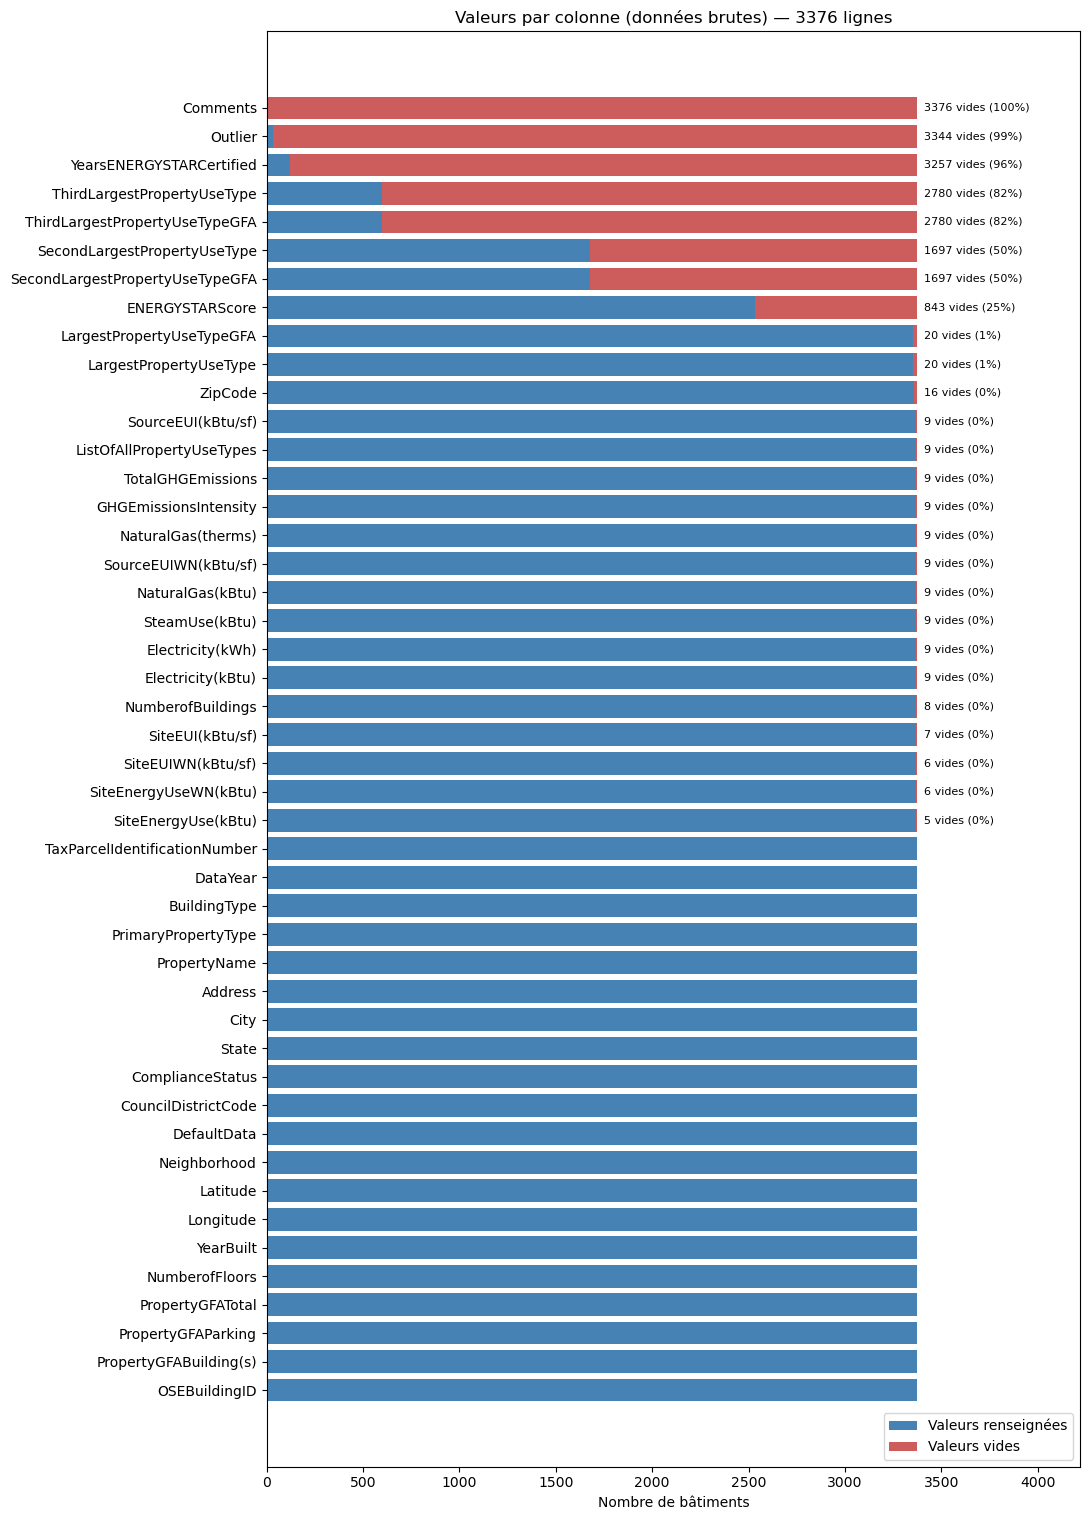

In [7]:
plot_valeurs_par_colonne(building_consumption, "Valeurs par colonne (données brutes)")  # appelle la fonction sur les données brutes

#### 1. Périmètre : ne garder que les bâtiments non destinés à l'habitation

In [8]:
print(building_consumption["BuildingType"].value_counts())  # compte les bâtiments par type (pour repérer les logements Multifamily)
print()
print(building_consumption["PrimaryPropertyType"].value_counts())  # compte les bâtiments par type de propriété principal

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

PrimaryPropertyType
Low-Rise Multifamily           987
Mid-Rise Multifamily           564
Small- and Mid-Sized Office    293
Other                          256
Warehouse                      187
Large Office                   173
K-12 School                    139
Mixed Use Property             133
High-Rise Multifamily          105
Retail Store                    91
Hotel                           77
Worship Facility                71
Distribution Center             53
Senior Care Community           45
Supermarket / Grocery Store     40
Medical Office                  39
Self-Storage Facility           28
University                      25
Residence Hall                  23
Refrigerated Warehouse          12
Restaura

`BuildingType` contient trois catégories de logements collectifs (`Multifamily LR / MR / HR`) qui sont **hors périmètre** de l'énoncé. Les types `NonResidential`, `Nonresidential COS`, `Nonresidential WA`, `SPS-District K-12` (écoles) et `Campus` sont conservés.

In [9]:
# 1) Suppression des logements
df = building_consumption.copy()  # copie de travail : on garde les données brutes intactes
filtre_logement = ~df["BuildingType"].str.contains("Multifamily", case=False, na=False)  # True pour les bâtiments dont le type ne contient PAS "Multifamily" (~ = négation)
suivre(df, df[filtre_logement], "Retrait des bâtiments Multifamily (habitation)")  # enregistre l'effet de ce filtre
df = df[filtre_logement].copy()  # applique le filtre : on ne garde que les lignes où le masque est vrai

Retrait des bâtiments Multifamily (habitation)                     3376 ->  1668  (-1708)


#### 2. Repérer les bâtiments aberrants ou peu pertinents
Colonnes utiles : `Outlier` (signalement par la ville), `ComplianceStatus`, `DefaultData` (valeurs par défaut non réelles) et le sens des valeurs (surfaces ou consommations nulles).

In [10]:
print(df["ComplianceStatus"].value_counts(), "\n")  # statuts de conformité du relevé (seuls les "Compliant" sont fiables)
print(df["Outlier"].value_counts(dropna=False), "\n")  # bâtiments signalés comme aberrants par la ville (dropna=False compte aussi les vides)
df_outliers = df[df["Outlier"].isin(["Low outlier", "High outlier"])]
display(df_outliers)
print(df["DefaultData"].value_counts())  # relevés basés sur des valeurs par défaut (non mesurées)

ComplianceStatus
Compliant                       1548
Error - Correct Default Data      88
Non-Compliant                     18
Missing Data                      14
Name: count, dtype: int64 

Outlier
NaN             1651
Low outlier       15
High outlier       2
Name: count, dtype: int64 



,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
226,350,2016,NonResidential,Large Office,Second And Spring Building,1100 Second Avenue,Seattle,WA,98101.0,0942000045,...,1.166315e+07,39794668.0,16048.309570,1604831.0,False,NaN,Non-Compliant,High outlier,362.66,2.10
384,539,2016,NonResidential,Retail Store,University Center,4501 Roosevelt Way NE,Seattle,WA,98105.0,5335200380,...,9.348260e+04,318963.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,2.22,0.03
448,608,2016,NonResidential,Large Office,411 1ST AVE S (ID608),411 1ST AVE S,Seattle,WA,98104.0,5247800200,...,4.715030e+05,1608768.0,3430.500488,343050.0,False,NaN,Non-Compliant,Low outlier,29.43,0.19
517,704,2016,NonResidential,Large Office,401 Elliott Ave West,401 Elliot Ave West,Seattle,WA,98119.0,7666202110,...,7.953454e+06,27137187.0,0.000000,0.0,False,NaN,Non-Compliant,High outlier,189.18,1.46
839,19967,2016,SPS-District K-12,K-12 School,Queen Anne Gym,1431 2nd Ave N,Seattle,WA,98109.0,0811000005,...,7.228240e+04,246628.0,1848.439575,184844.0,True,NaN,Error - Correct Default Data,Low outlier,11.54,0.32
1045,20617,2016,NonResidential,Retail Store,Seattle Habitat Store,21 S Nevada St,Seattle,WA,98134.0,1824049074,...,1.436250e+04,49005.0,964.640015,96464.0,True,NaN,Error - Correct Default Data,Low outlier,5.46,0.14
1229,21315,2016,NonResidential,Small- and Mid-Sized Office,1518 Fifith Ave,1520 Fifth Ave,Seattle,WA,98101.0,1975700135,...,7.064900e+03,24105.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.17,0.00
1295,21474,2016,NonResidential,Other,The Lusty Lady,1315 1st Ave,Seattle,WA,98101.0,1976200060,...,1.298170e+04,44294.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.31,0.01
1611,22830,2016,NonResidential,Worship Facility,Freedom Church,9601 35th Ave,Seattle,WA,98126.0,2858600090,...,2.955500e+04,100842.0,0.000000,0.0,False,NaN,Non-Compliant,Low outlier,0.70,0.03
1945,23912,2016,NonResidential,Small- and Mid-Sized Office,1416 S Jackson,1416 South Jackson Street,Seattle,WA,98133.0,3320000165,...,4.155460e+04,141784.0,1430.729858,143073.0,False,NaN,Non-Compliant,Low outlier,8.59,0.19


DefaultData
False    1580
True       88
Name: count, dtype: int64


In [11]:
# 2) Bâtiments dont le relevé n'est pas fiable
filtre_compliant = df["ComplianceStatus"] == "Compliant"  # True si le relevé est conforme
suivre(df, df[filtre_compliant], "Conservation des seuls relevés 'Compliant'")  
df = df[filtre_compliant].copy()  # applique le filtre

filtre_outlier = df["Outlier"].isna()  # True si la ville n'a pas signalé le bâtiment comme aberrant (colonne vide)
suivre(df, df[filtre_outlier], "Retrait des outliers signalés par la ville (colonne Outlier)") 
df = df[filtre_outlier].copy()  # applique le filtre

filtre_valeur_defaut = ~df["DefaultData"]  # True si le relevé n'est PAS basé sur des données par défaut
suivre(df, df[filtre_valeur_defaut], "Retrait des relevés basés sur des données par défaut") 
df = df[filtre_valeur_defaut].copy()  # applique le filtre

Conservation des seuls relevés 'Compliant'                         1668 ->  1548  (-120)
Retrait des outliers signalés par la ville (colonne Outlier)       1548 ->  1548  (-0)
Retrait des relevés basés sur des données par défaut               1548 ->  1548  (-0)


#### 3. Choix des cibles et valeurs manquantes
Colonnes candidates : `SiteEnergyUse(kBtu)`, `SiteEnergyUseWN(kBtu)` (normalisée météo), `TotalGHGEmissions`, `GHGEmissionsIntensity`.
**Choix : deux cibles — `SiteEnergyUse(kBtu)` (consommation totale réelle d'énergie) et `TotalGHGEmissions` (émissions de CO2 en tonnes équivalent CO2)**, comme demandé par le projet. Les colonnes `SiteEUI`, `SourceEUI`, `Electricity`, `NaturalGas`, `SteamUse`, `GHGEmissionsIntensity`, `SiteEnergyUseWN` en sont dérivées ou directement liées : **elles ne seront pas utilisées comme features (data leakage)**. Pour la même raison, la consommation n'est pas une feature de la prédiction du CO2, et inversement.

In [12]:
manquants = df.isna().sum()  # nombre de valeurs vides par colonne
manquants = manquants[manquants > 0].sort_values(ascending=False)  # garde les colonnes avec des vides, de la plus vide à la moins vide
pd.DataFrame({"manquants": manquants, "%": (manquants / len(df) * 100).round(1)})  # tableau : nombre et pourcentage de vides par colonne

,manquants,%
Comments,1548,100.0
Outlier,1548,100.0
YearsENERGYSTARCertified,1451,93.7
ThirdLargestPropertyUseType,1200,77.5
ThirdLargestPropertyUseTypeGFA,1200,77.5
SecondLargestPropertyUseType,706,45.6
SecondLargestPropertyUseTypeGFA,706,45.6
ENERGYSTARScore,551,35.6
ZipCode,13,0.8
LargestPropertyUseType,4,0.3


Lecture des valeurs manquantes :
- `Comments` (100 %) et `Outlier` (nul après filtrage) : colonnes vides, à supprimer.
- `YearsENERGYSTARCertified` (93.7 %) et `ENERGYSTARScore` (35.6 %) : absentes pour les bâtiments non éligibles/non évalués. Le score est calculé **à partir de la consommation** (leakage) et très incomplet : on le supprime.
- `SecondLargestPropertyUseType(GFA)` et `ThirdLargest...` : valeurs manquantes **structurelles** = le bâtiment n'a qu'un seul (ou deux) usage(s). Ce n'est pas un trou de donnée, c'est une information (on s'en servira pour créer le nombre d'usages).
- Les rares NaN restants (consommation, émissions, GFA principale…) concernent très peu de lignes.

In [13]:
#Cohérence : consommation, émissions, surfaces, étages, année de construction
cols_check = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions", "PropertyGFATotal", "PropertyGFABuilding(s)","NumberofFloors", "NumberofBuildings", "YearBuilt", "SiteEUI(kBtu/sf)"]  # (cibles, surfaces, étages, année, intensité)
df[cols_check].describe().T  # statistiques (min, max, médiane...) pour détecter les valeurs impossibles (0, négatif)

,count,mean,std,min,25%,50%,75%,max
SiteEnergyUse(kBtu),1548.0,8.860058e+06,3.130568e+07,57133.19922,1.251083e+06,2732166.875,7.294487e+06,8.739237e+08
TotalGHGEmissions,1548.0,1.936089e+02,7.791053e+02,-0.80000,2.065500e+01,49.845,1.472275e+02,1.687098e+04
PropertyGFATotal,1548.0,1.213321e+05,3.062944e+05,11285.00000,2.884325e+04,48159.000,1.076615e+05,9.320156e+06
PropertyGFABuilding(s),1548.0,1.074898e+05,2.926272e+05,3636.00000,2.793675e+04,46084.000,9.556825e+04,9.320156e+06
NumberofFloors,1548.0,4.276486e+00,6.780694e+00,0.00000,1.000000e+00,2.000,4.000000e+00,9.900000e+01
NumberofBuildings,1548.0,1.178941e+00,3.039221e+00,0.00000,1.000000e+00,1.000,1.000000e+00,1.110000e+02
YearBuilt,1548.0,1.961644e+03,3.288692e+01,1900.00000,1.930000e+03,1965.500,1.989000e+03,2.015000e+03
SiteEUI(kBtu/sf),1548.0,7.508411e+01,7.521284e+01,1.40000,3.490000e+01,53.750,8.520000e+01,8.344000e+02


In [14]:
#Retrait des lignes sans cible ou avec des valeurs incohérentes
filtre_SiteEnergyUse_positif = df["SiteEnergyUse(kBtu)"].notna() & (df["SiteEnergyUse(kBtu)"] > 0)  # cible énergie présente ET strictement positive
suivre(df, df[filtre_SiteEnergyUse_positif], "Cible énergie manquante ou <= 0") 
df = df[filtre_SiteEnergyUse_positif].copy() 

filtre_TotalGHGEmissions_positif = df["TotalGHGEmissions"].notna() & (df["TotalGHGEmissions"] > 0)  # cible CO2 présente ET strictement positive
suivre(df, df[filtre_TotalGHGEmissions_positif], "Cible émissions CO2 manquante ou <= 0") 
df = df[filtre_TotalGHGEmissions_positif].copy()

filtre_GFA_positif = (df["PropertyGFATotal"] > 0) & (df["PropertyGFABuilding(s)"] > 0)  # surfaces totale et bâtie strictement positives
suivre(df, df[filtre_GFA_positif], "Surface totale/bâtiment nulle")
df = df[filtre_GFA_positif].copy() 

filtre_etage_null = df["NumberofFloors"] > 0  # au moins 1 étage (0 étage est incohérent)
suivre(df, df[filtre_etage_null], "Nombre d'étages = 0") 
df = df[filtre_etage_null].copy() 

filtre_nb_batiment = df["NumberofBuildings"].fillna(1) > 0  # au moins 1 bâtiment (un vide est remplacé par 1 pour ne pas supprimer la ligne)
suivre(df, df[filtre_nb_batiment], "Nombre de bâtiments = 0") 
df = df[filtre_nb_batiment].copy() 

filtre_parking_superieur_total = df["PropertyGFAParking"] <= df["PropertyGFATotal"]  # le parking ne peut pas être plus grand que la surface totale
suivre(df, df[filtre_parking_superieur_total], "Surface parking > surface totale") 
df = df[filtre_parking_superieur_total].copy() 

print("\nBâtiments restants :", len(df))  # affiche le nombre de bâtiments restants

Cible énergie manquante ou <= 0                                    1548 ->  1548  (-0)
Cible émissions CO2 manquante ou <= 0                              1548 ->  1546  (-2)
Surface totale/bâtiment nulle                                      1546 ->  1546  (-0)
Nombre d'étages = 0                                                1546 ->  1530  (-16)
Nombre de bâtiments = 0                                            1530 ->  1479  (-51)
Surface parking > surface totale                                   1479 ->  1479  (-0)

Bâtiments restants : 1479


In [15]:
#Nettoyage des libellés : quartiers écrits avec des casses différentes
print(df["Neighborhood"].unique())
df["Neighborhood"] = df["Neighborhood"].str.upper().replace({"DELRIDGE NEIGHBORHOODS": "DELRIDGE"})  #met en majuscules et fusionne deux écritures du même quartier
print(df["Neighborhood"].value_counts())  #vérifier le nombre de bâtiments par quartier après harmonisation

['DOWNTOWN' 'NORTHEAST' 'EAST' 'LAKE UNION' 'GREATER DUWAMISH'
 'MAGNOLIA / QUEEN ANNE' 'BALLARD' 'NORTHWEST' 'CENTRAL' 'SOUTHWEST'
 'SOUTHEAST' 'DELRIDGE' 'NORTH' 'Delridge' 'North' 'Ballard' 'Northwest'
 'Central' 'DELRIDGE NEIGHBORHOODS']
Neighborhood
DOWNTOWN                 335
GREATER DUWAMISH         320
MAGNOLIA / QUEEN ANNE    140
LAKE UNION               138
NORTHEAST                107
EAST                     105
NORTHWEST                 75
BALLARD                   63
NORTH                     56
CENTRAL                   44
DELRIDGE                  38
SOUTHWEST                 29
SOUTHEAST                 29
Name: count, dtype: int64


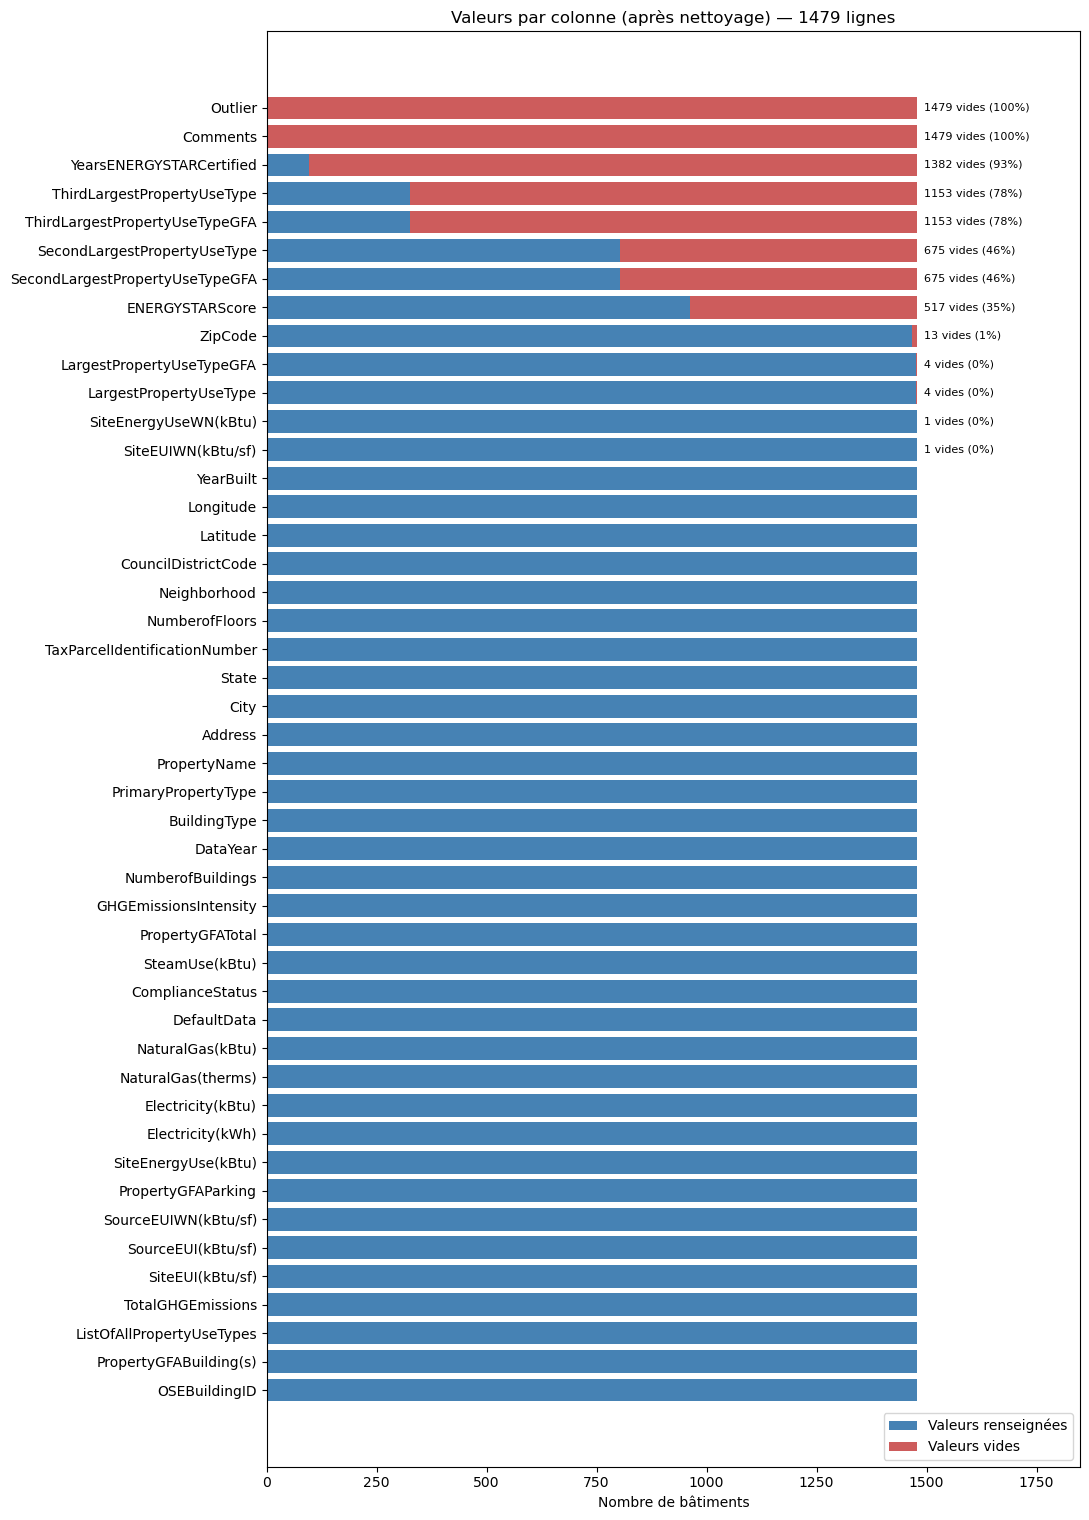

In [16]:
#Nombre de valeurs par colonne et valeurs vides APRÈS nettoyage
plot_valeurs_par_colonne(df, "Valeurs par colonne (après nettoyage)")  # même graphique qu'au début, pour comparer avant/après

Après filtrage, les colonnes cibles et les colonnes structurelles utiles (surfaces, étages, année, localisation, type) sont **complètes**. Les colonnes encore très vides (`Comments`, `Outlier`, `YearsENERGYSTARCertified`, usages secondaire/tertiaire) sont soit inutilisables, soit des vides « structurels » (pas de 2ᵉ ou 3ᵉ usage).

#### 4. Colonnes conservées / supprimées
| Groupe | Colonnes | Décision |
|---|---|---|
| Identifiants / texte libre | `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber`, `City`, `State`, `DataYear`, `Comments` | Supprimées (non informatives ou constantes) |
| Qualité du relevé | `ComplianceStatus`, `Outlier`, `DefaultData` | Servent au filtrage puis supprimées |
| Structure | `YearBuilt`, `NumberofFloors`, `NumberofBuildings`, `PropertyGFA*`, usages & surfaces des usages | **Conservées** |
| Localisation | `Neighborhood`, `Latitude`, `Longitude`, `CouncilDistrictCode`, `ZipCode` | Conservées (`Neighborhood`, lat/long) |
| Type | `BuildingType`, `PrimaryPropertyType`, `LargestPropertyUseType` | Conservées |
| Consommation / émissions | `SiteEUI*`, `SourceEUI*`, `SiteEnergyUseWN`, `Electricity*`, `NaturalGas*`, `SteamUse`, `GHGEmissionsIntensity`, `ENERGYSTARScore` | **Supprimées des features** (leakage) — seules les deux cibles sont gardées |

#### 5. Statistiques descriptives et visualisations des cibles

In [17]:
cibles = {"SiteEnergyUse(kBtu)": "Consommation d'énergie (kBtu)", "TotalGHGEmissions": "Émissions de CO2 (tonnes éq. CO2)"}
df[list(cibles)].describe().round(1).T  #statistiques des deux cibles (moyenne, médiane, etc)

,count,mean,std,min,25%,50%,75%,max
SiteEnergyUse(kBtu),1479.0,8178550.1,22539018.3,57133.2,1222024.7,2661488.0,7223922.5,448385312.0
TotalGHGEmissions,1479.0,183.6,740.0,0.4,20.2,49.2,142.9,16871.0


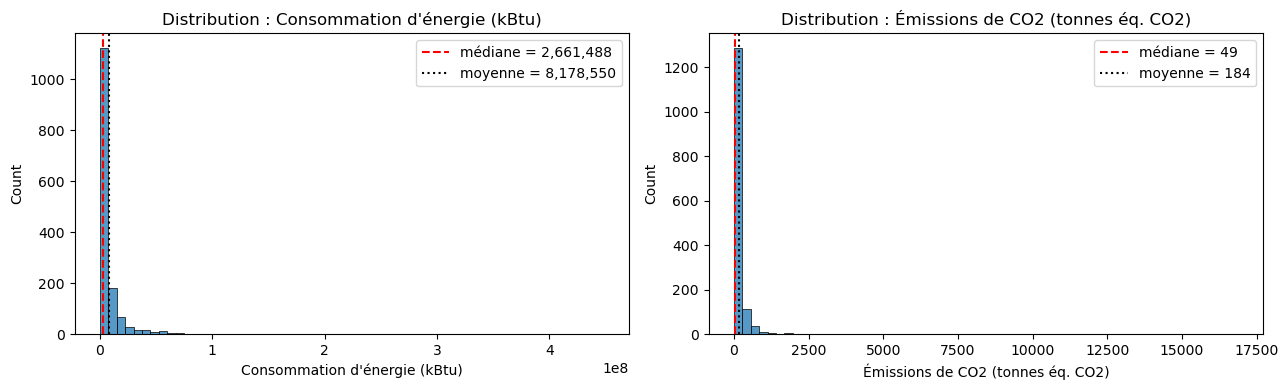

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (col, lib) in zip(ax, cibles.items()):
    sns.histplot(df[col], bins=60, ax=a)  # histogramme : combien de bâtiments par tranche de valeur
    a.axvline(df[col].median(), color="red", ls="--", label=f"médiane = {df[col].median():,.0f}") 
    a.axvline(df[col].mean(), color="black", ls=":", label=f"moyenne = {df[col].mean():,.0f}")
    a.set_title(f"Distribution : {lib}"); a.set_xlabel(lib); a.legend()
plt.tight_layout(); 
plt.show()

**Interprétation des statistiques descriptives des cibles**
- **Énergie** : médiane ≈ 2,7 M kBtu mais moyenne ≈ 8,2 M kBtu (3 fois la médiane) ; écart-type (≈ 22,5 M) très supérieur à la moyenne ; maximum à 448 M kBtu.
- **CO2** : médiane ≈ 49 tonnes, moyenne ≈ 184 t, maximum ≈ 16 900 t.
- Dans les deux cas, la distribution est **fortement asymétrique à droite** : une grande majorité de bâtiments « modestes » et une poignée de très gros émetteurs/consommateurs (hôpitaux, grands bureaux, laboratoires) qui tirent la moyenne vers le haut. La **médiane** est donc plus représentative que la moyenne.

Conséquences pour la suite :
- seuils d'outliers basés sur des **quantiles** plutôt que sur l'IQR car elle va qualifier une part massive de grands bâtiments légitimes (hôpitaux, grands bureaux) comme des outliers, alors qu'il s'agit de profils réels et importants pour le modèle.
Utilisation des quantiles pour décider précisément de la proportion de données extrêmes à écarter (fixer un seuil à 99% et retirer les 1% de valeurs les plus extrêmes) 
- lecture des métriques en tenant compte du fait que les erreurs absolues sont dominées par les gros bâtiments.

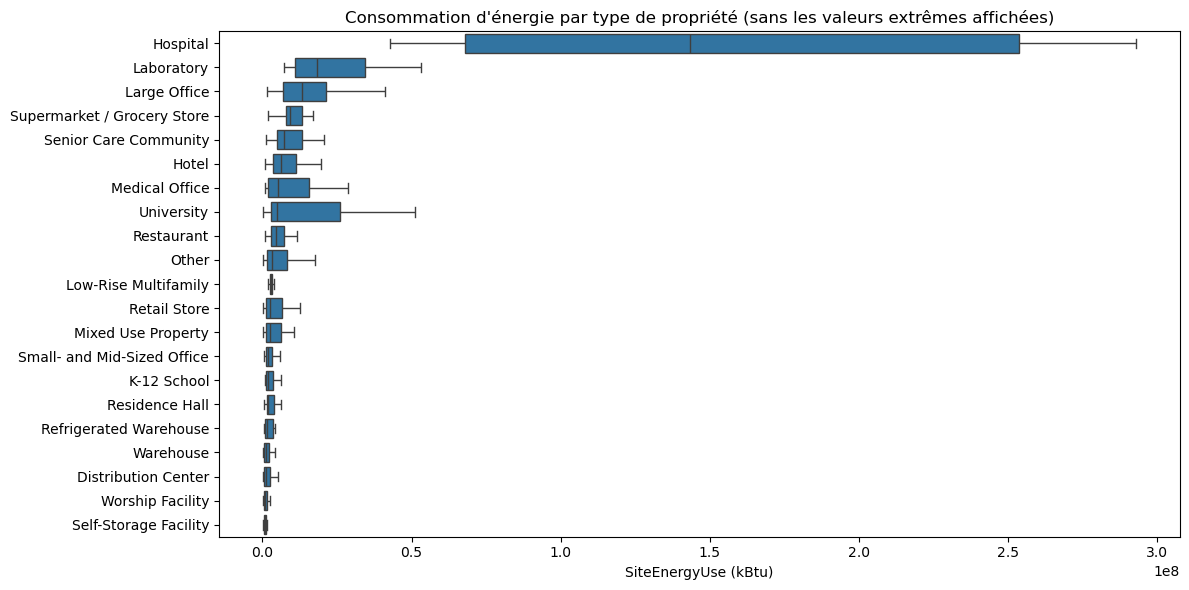

In [19]:
# Quanti vs quali : consommation par type de propriété
ordre = df.groupby("PrimaryPropertyType")["SiteEnergyUse(kBtu)"].median().sort_values(ascending=False).index  # classe les types de propriété du plus au moins consommateur (médiane)
plt.figure(figsize=(12, 6))  # crée une figure de 12 x 6 pouces
sns.boxplot(data=df, y="PrimaryPropertyType", x="SiteEnergyUse(kBtu)", order=ordre, showfliers=False)  # boîtes à moustaches : une variable qualitative contre une quantitative (sans afficher les points extrêmes)
plt.title("Consommation d'énergie par type de propriété (sans les valeurs extrêmes affichées)")  # titre du graphique
plt.xlabel("SiteEnergyUse (kBtu)"); plt.ylabel("")  # légende de l'axe horizontal, pas de légende verticale
plt.tight_layout(); plt.show()  # ajuste les marges puis affiche

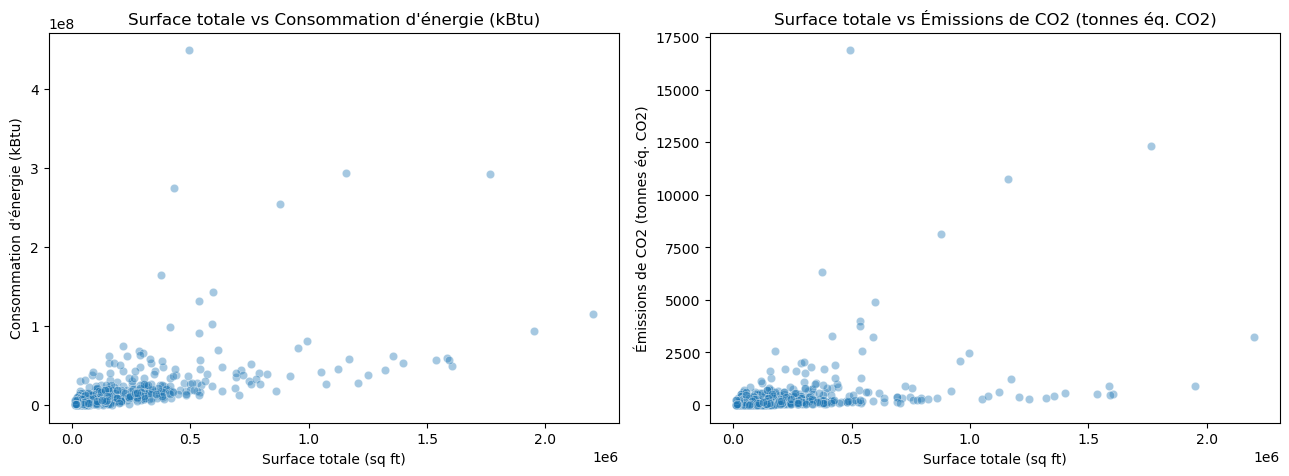

In [20]:
# Quanti vs quanti : surface vs consommation et émissions
fig, ax = plt.subplots(1, 2, figsize=(13, 5)) 
for a, (col, lib) in zip(ax, cibles.items()): 
    sns.scatterplot(data=df, x="PropertyGFATotal", y=col, alpha=0.4, ax=a)  # nuage de points : surface (x) contre cible (y), transparence pour voir les superpositions
    a.set_title(f"Surface totale vs {lib}"); a.set_xlabel("Surface totale (sq ft)"); a.set_ylabel(lib)  # titre et légendes des axes
plt.tight_layout(); plt.show()  

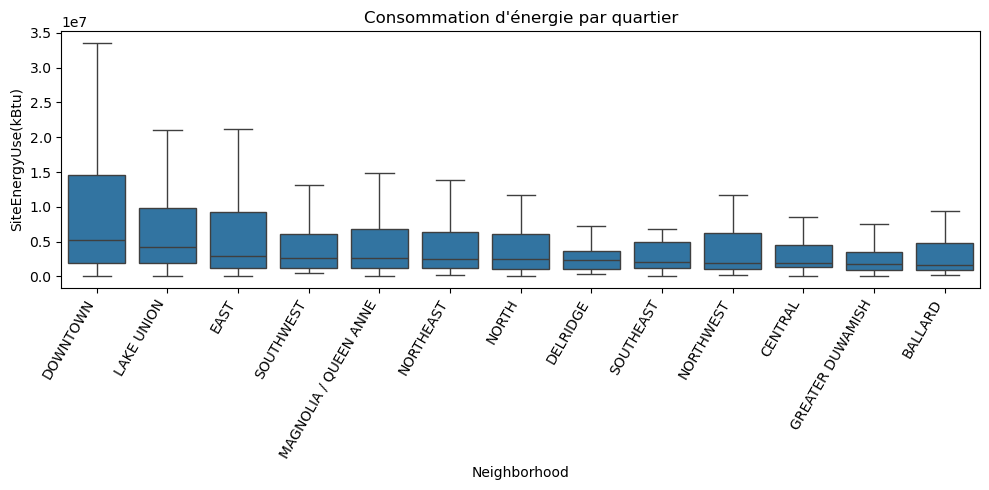

In [21]:
# Quali vs quanti : par quartier
ordre = df.groupby("Neighborhood")["SiteEnergyUse(kBtu)"].median().sort_values(ascending=False).index  # classe les quartiers par consommation médiane décroissante
plt.figure(figsize=(10, 5))  # crée une figure de 10 x 5 pouces
sns.boxplot(data=df, x="Neighborhood", y="SiteEnergyUse(kBtu)", order=ordre, showfliers=False)  #consommation par quartier
plt.xticks(rotation=60, ha="right")
plt.title("Consommation d'énergie par quartier")  # titre du graphique
plt.tight_layout(); plt.show()

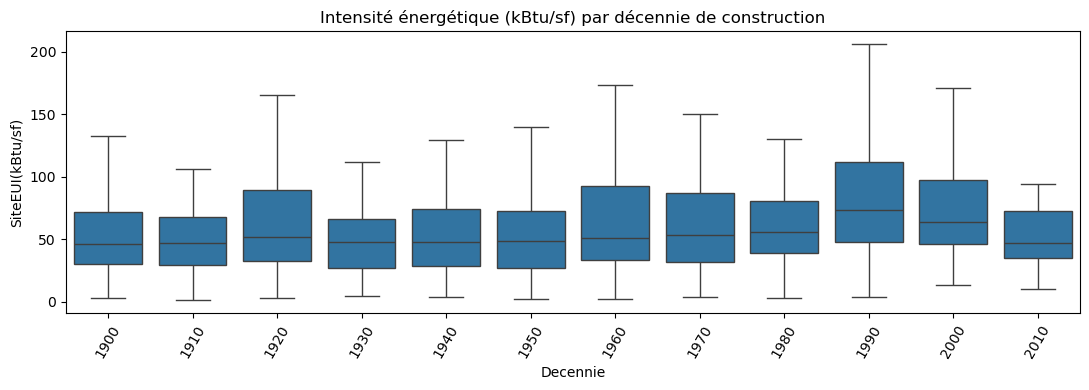

In [22]:
#temporalité : consommation par unité de surface selon la décennie de construction
df["Decennie"] = (df["YearBuilt"] // 10 * 10).astype(int)  # arrondit l'année à la décennie (1987 -> 1980) pour regrouper les bâtiments
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x="Decennie", y="SiteEUI(kBtu/sf)", showfliers=False)  # intensité énergétique (kBtu par pied carré) selon la décennie de construction
plt.xticks(rotation=60)
plt.title("Intensité énergétique (kBtu/sf) par décennie de construction")
plt.tight_layout(); plt.show() 
df = df.drop(columns="Decennie")

- Périmètre : de **3 376** relevés, il reste **1 479** bâtiments non résidentiels exploitables après nettoyage (voir le suivi des lignes).
- La **surface** est le premier moteur de la consommation et des émissions : plus un bâtiment est grand, plus il consomme et émet.
- Le **type d'usage** change fortement la consommation : un hôpital médian consomme ~58 M kBtu et émet ~1 800 t de CO2 contre ~1,3 M kBtu et ~25 t pour un entrepôt (valeurs médianes du jeu de modélisation).
- L'**âge** du bâtiment n'a pas de lien net avec l'intensité énergétique (pas d'effet monotone par décennie) : la date de construction seule est peu informative.
- Les valeurs vides sont soit **sans objet** (`Comments`, `Outlier`), soit **structurelles** (pas de 2ᵉ/3ᵉ usage), soit **liées à la consommation** (`ENERGYSTARScore`) : on ne supprime donc pas toutes les lignes incomplètes.

# Modélisation

### Import des modules

In [23]:
# Selection
from sklearn.model_selection import (  # outils de sklearn pour séparer et valider les données
    train_test_split,  # sépare les données en jeu d'entraînement et jeu de test
    GridSearchCV,  # cherche automatiquement les meilleurs hyperparamètres
    cross_validate,  # validation croisée : évalue un modèle sur plusieurs découpages
    KFold,  # définit comment découper les données pour la validation croisée
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error  # métriques d'évaluation : erreur quadratique, R², erreur absolue moyenne
from sklearn.inspection import permutation_importance  # mesure l'importance des variables en les mélangeant une à une

# Preprocess
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor  # appliquer des traitements différents par colonne ; transformer la cible (log) pendant l'apprentissage
from sklearn.pipeline import Pipeline  # enchaîner des étapes (préparation puis modèle) en un seul objet
from sklearn.impute import SimpleImputer  # remplacer les valeurs vides par une valeur (ici la médiane)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, FunctionTransformer  # encodage des catégories, mise à l'échelle, application d'une fonction (log)

# Modèles
from sklearn.dummy import DummyRegressor  # modèle « bête » qui prédit toujours la même valeur : sert de référence
from sklearn.linear_model import LinearRegression  # régression linéaire : modèle simple et interprétable
from sklearn.svm import SVR  # machine à vecteurs de support pour la régression : modèle non linéaire à noyau
from sklearn.ensemble import RandomForestRegressor  # forêt aléatoire : ensemble d'arbres de décision, modèle non linéaire7

#GridSearch
from sklearn.model_selection import RandomizedSearchCV

### Feature Engineering

Nouvelles features construites **uniquement à partir d'informations structurelles** (aucune valeur de consommation ou d'émission → pas de data leakage) :
- **Temporalité** : âge du bâtiment, tranche d'époque de construction.
- **Structure** : surface moyenne par étage, par bâtiment, part de parking, présence de parking.
- **Usages** : nombre d'usages, parts de surface des usages principal/secondaire/tertiaire, indicateur « multi-usage ».
- **Localisation** : distance au centre-ville (Downtown), quartier.
- **Haute cardinalité** : `LargestPropertyUseType` (56 modalités) regroupé en 12 catégories + « Other ».

In [24]:
data = df.copy()  #copie de travail : on enrichit `data` sans toucher à `df`

#Temporalité
data["Age_batiments"] = 2016 - data["YearBuilt"]  #âge du bâtiment au moment du relevé (plus parlant que l'année)
data["Tranche_age_batiment"] = pd.cut(data["YearBuilt"], bins=[1800, 1920, 1945, 1970, 1990, 2005, 2016],
                          labels=["<1920", "1920-45", "1945-70", "1970-90", "1990-2005", "2005+"]).astype(str)  #nom de chaque tranche, converti en texte

#Structure
data["NumberofBuildings"] = data["NumberofBuildings"].fillna(1)  #un nombre de bâtiments vide est supposé égal à 1
data["GFAPerFloor"] = data["PropertyGFATotal"] / data["NumberofFloors"]  #surface moyenne par étage : emprise au sol du bâtiment
data["GFAPerBuilding"] = data["PropertyGFATotal"] / data["NumberofBuildings"]  #surface moyenne par bâtiment (utile pour les campus)
data["ParkingRatio"] = data["PropertyGFAParking"] / data["PropertyGFATotal"]  #part de la surface occupée par le parking
data["HasParking"] = (data["PropertyGFAParking"] > 0).astype(int)  #1 si le bâtiment a un parking, sinon 0

#Usages
for c in ["SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA"]:  #pour les surfaces du 2e et 3e usage
    data[c] = data[c].fillna(0)  #un vide signifie « pas de 2e/3e usage » donc surface 0
data["NumUseTypes"] = (data["LargestPropertyUseType"].notna().astype(int)  #compte 1 si un usage principal existe
                       + data["SecondLargestPropertyUseType"].notna().astype(int)  #+ 1 si un 2e usage existe
                       + data["ThirdLargestPropertyUseType"].notna().astype(int))  #+ 1 si un 3e usage existe : donne le nombre d'usages du bâtiment
data["IsMultiUse"] = (data["NumUseTypes"] > 1).astype(int)  #1 si le bâtiment a plusieurs usages

# Regroupement de la haute cardinalité
data["LargestPropertyUseType"] = data["LargestPropertyUseType"].fillna("Unknown")  #les usages vides deviennent « Unknown » plutôt que d'être perdus
#top_usages = data["LargestPropertyUseType"].value_counts().head(12).index  #les 12 usages principaux les plus fréquents
#data["LargestUseGroup"] = np.where(data["LargestPropertyUseType"].isin(top_usages),  #si l'usage fait partie des 12 plus fréquents...
 #                                  data["LargestPropertyUseType"], "Other")  #on le garde, sinon on le range dans « Other » (évite trop de colonnes après encodage)

def haversine_km(lat1, lon1, lat2, lon2):  #fonction qui calcule une distance en km entre deux points GPS
    """Distance à vol d'oiseau en km."""
    r = 6371  # rayon de la Terre en km
    p1, p2 = np.radians(lat1), np.radians(lat2)  #convertit les latitudes de degrés en radians (unité attendue par sin/cos)
    dphi = p2 - p1  #écart de latitude
    dl = np.radians(lon2 - lon1)  #écart de longitude converti en radians
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2  #formule de haversine : tient compte de la courbure de la Terre
    return 2 * r * np.arcsin(np.sqrt(a))  #convertit en distance en km
    
#Localisation (centre-ville de Seattle ~ 47.6062, -122.3321)
data["DistDowntownKm"] = haversine_km(data["Latitude"], data["Longitude"], 47.6062, -122.3321)  # distance de chaque bâtiment au centre-ville

#l'électricité est présente dans quasiment tous les bâtiments -> feature non discriminante, non créée.

data[["Age_batiments", "Tranche_age_batiment", "GFAPerFloor", "ParkingRatio", "NumUseTypes",  # aperçu des nouvelles variables créées
      "DistDowntownKm"]].head()  #on regarde les 5 premières lignes

,Age_batiments,Tranche_age_batiment,GFAPerFloor,ParkingRatio,NumUseTypes,DistDowntownKm
0,89,1920-45,7369.500000,0.000000,1,0.800050
1,20,1990-2005,9415.090909,0.145453,3,0.787077
2,47,1945-70,23319.756098,0.205748,1,0.970109
3,90,1920-45,6132.000000,0.000000,1,0.944139
4,36,1970-90,9754.444444,0.353115,3,1.048092


In [25]:
#Contrôle de la qualité des features créées : lien (corrélation de rang de Spearman) avec les deux cibles
nouvelles = ["Age_batiments", "GFAPerFloor", "GFAPerBuilding", "ParkingRatio", "HasParking", "NumUseTypes",  # liste des variables créées à contrôler
             "IsMultiUse", "DistDowntownKm"]  # (suite de la liste)
qualite = data[nouvelles + list(cibles)].corr(method="spearman").loc[nouvelles, list(cibles)]  # corrélation de Spearman (robuste aux valeurs extrêmes) entre chaque feature et chaque cible
qualite.sort_values("SiteEnergyUse(kBtu)", key=abs, ascending=False).round(2)  # classe du plus au moins corrélé à l'énergie (en valeur absolue)

,SiteEnergyUse(kBtu),TotalGHGEmissions
GFAPerBuilding,0.70,0.53
GFAPerFloor,0.35,0.30
HasParking,0.33,0.18
ParkingRatio,0.33,0.18
Age_batiments,-0.27,-0.16
DistDowntownKm,-0.27,-0.19
NumUseTypes,0.24,0.15
IsMultiUse,0.22,0.13


Les features créées présentent des liens cohérents avec les cibles (surface par bâtiment et par étage, présence de gaz/vapeur, nombre d'usages, distance au centre), ce qui confirme leur intérêt. Aucune n'est calculée à partir des cibles.

### Préparation des features pour la modélisation

#### Suppression des colonnes peu pertinentes / sources de leakage

In [26]:
targets = list(cibles)   # ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]
num_features = ["Age_batiments", "NumberofFloors", "NumberofBuildings", "PropertyGFATotal",  # liste des variables numériques candidates
                "PropertyGFAParking", "PropertyGFABuilding(s)", "GFAPerFloor", "GFAPerBuilding", "ParkingRatio",  # surfaces, étages, parking
                "HasParking", "NumUseTypes",  # usages
                "IsMultiUse", "LargestPropertyUseTypeGFA", "Latitude", "Longitude", "DistDowntownKm"] 
cat_features = ["BuildingType", "PrimaryPropertyType", "Neighborhood", "Tranche_age_batiment"]  # variables catégorielles (du texte) à encoder plus tard

model_df = data[num_features + cat_features + targets].copy()  # tableau final : uniquement features retenues + cibles (tout le reste, dont colonnes de fuite, est exclu)
print(model_df.shape)  # dimensions du tableau de modélisation
print(model_df.isna().sum()[model_df.isna().sum() > 0])  # colonnes qui contiennent encore des vides (à imputer plus tard)

(1479, 22)
LargestPropertyUseTypeGFA    4
dtype: int64


#### Distribution des cibles et traitement des outliers

In [27]:
print(model_df[targets].describe().round(0).T)  # statistiques des deux cibles avant retrait des extrêmes
print(model_df[targets].quantile([.01, .05, .5, .95, .99]).round(0).T)  # quantiles 1 %, 5 %, 50 %, 95 %, 99 % pour choisir les seuils d'outliers

                      count       mean         std      min        25%  \
SiteEnergyUse(kBtu)  1479.0  8178550.0  22539018.0  57133.0  1222025.0   
TotalGHGEmissions    1479.0      184.0       740.0      0.0       20.0   

                           50%        75%          max  
SiteEnergyUse(kBtu)  2661488.0  7223922.0  448385312.0  
TotalGHGEmissions         49.0      143.0      16871.0  
                         0.01      0.05       0.50        0.95        0.99
SiteEnergyUse(kBtu)  174545.0  439015.0  2661488.0  30042991.0  73134134.0
TotalGHGEmissions         1.0       4.0       49.0       567.0      2063.0


La méthode IQR supprimerait un grand nombre de gros bâtiments (distributions très asymétriques). On utilise donc des **seuils par quantiles** (1 % et 99 %) pour ne retirer que les valeurs réellement extrêmes. Pour que les deux modèles soient comparables, on ne garde que les bâtiments **non extrêmes sur les deux cibles** (mêmes lignes pour les deux modélisations).

### Correction : 
Dans le test je retire aussi les batiments dont l'energie dépensées est volumineuse, ce qui rend "facile" le test. Il faut seulement mettre le filtre dans le train mais bien prendre en compte ces batiments dans le test pour avoir les données les plus réels possibles dans le test. Je retire donc cette partie et je le fait après le split en 5 partie

#### Features redondantes : matrice de corrélation

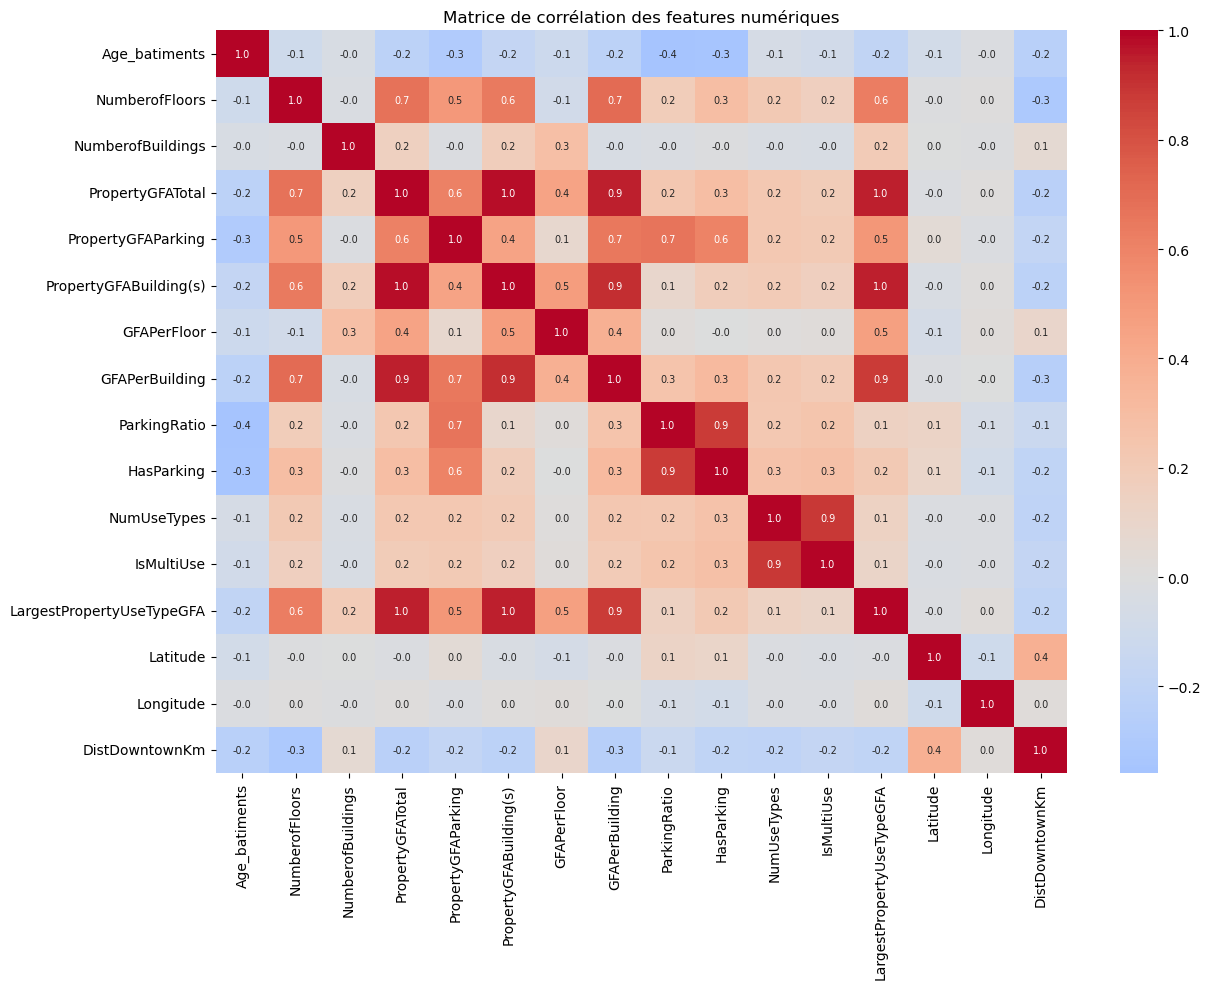

Paires |corr| > 0.7 : [('NumberofFloors', 'GFAPerBuilding', np.float64(0.71)), ('PropertyGFATotal', 'PropertyGFABuilding(s)', np.float64(0.98)), ('PropertyGFATotal', 'GFAPerBuilding', np.float64(0.95)), ('PropertyGFATotal', 'LargestPropertyUseTypeGFA', np.float64(0.95)), ('PropertyGFABuilding(s)', 'GFAPerBuilding', np.float64(0.91)), ('PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', np.float64(0.95)), ('GFAPerBuilding', 'LargestPropertyUseTypeGFA', np.float64(0.87)), ('ParkingRatio', 'HasParking', np.float64(0.87)), ('NumUseTypes', 'IsMultiUse', np.float64(0.89))]


In [28]:
corr = model_df[num_features].corr()  #matrice de corrélation entre toutes les features numériques (valable seulement pour du numérique)
plt.figure(figsize=(13, 10))  # crée une grande figure
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})  # carte de chaleur : rouge = corrélation positive, bleu = négative
plt.title("Matrice de corrélation des features numériques")
plt.tight_layout(); plt.show()

paires = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]  # liste toutes les paires de features (sans doublon)...
          if abs(corr.loc[a, b]) > 0.7]  # ...dont la corrélation dépasse 0,9 : elles apportent la même information
print("Paires |corr| > 0.7 :", paires)  # affiche les paires redondantes

In [29]:
#On retire un membre de chaque paire redondante (on garde la plus interprétable)
redondantes = ["PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA", "IsMultiUse", "HasParking", "GFAPerBuilding"]  # features redondantes choisies d'après les paires ci-dessus
redondantes = [c for c in redondantes if c in num_features]  # sécurité : on ne garde que celles qui existent encore dans la liste
num_features = [c for c in num_features if c not in redondantes]  # retire ces features de la liste des features numériques
model_df = model_df.drop(columns=redondantes)  # retire aussi ces colonnes du tableau
print("Retirées :", redondantes)  # affiche ce qui a été retiré
print("Features numériques restantes :", num_features)  # affiche la liste finale des features numériques

Retirées : ['PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'IsMultiUse', 'HasParking', 'GFAPerBuilding']
Features numériques restantes : ['Age_batiments', 'NumberofFloors', 'NumberofBuildings', 'PropertyGFATotal', 'PropertyGFAParking', 'GFAPerFloor', 'ParkingRatio', 'NumUseTypes', 'Latitude', 'Longitude', 'DistDowntownKm']


#### Lien features / cibles

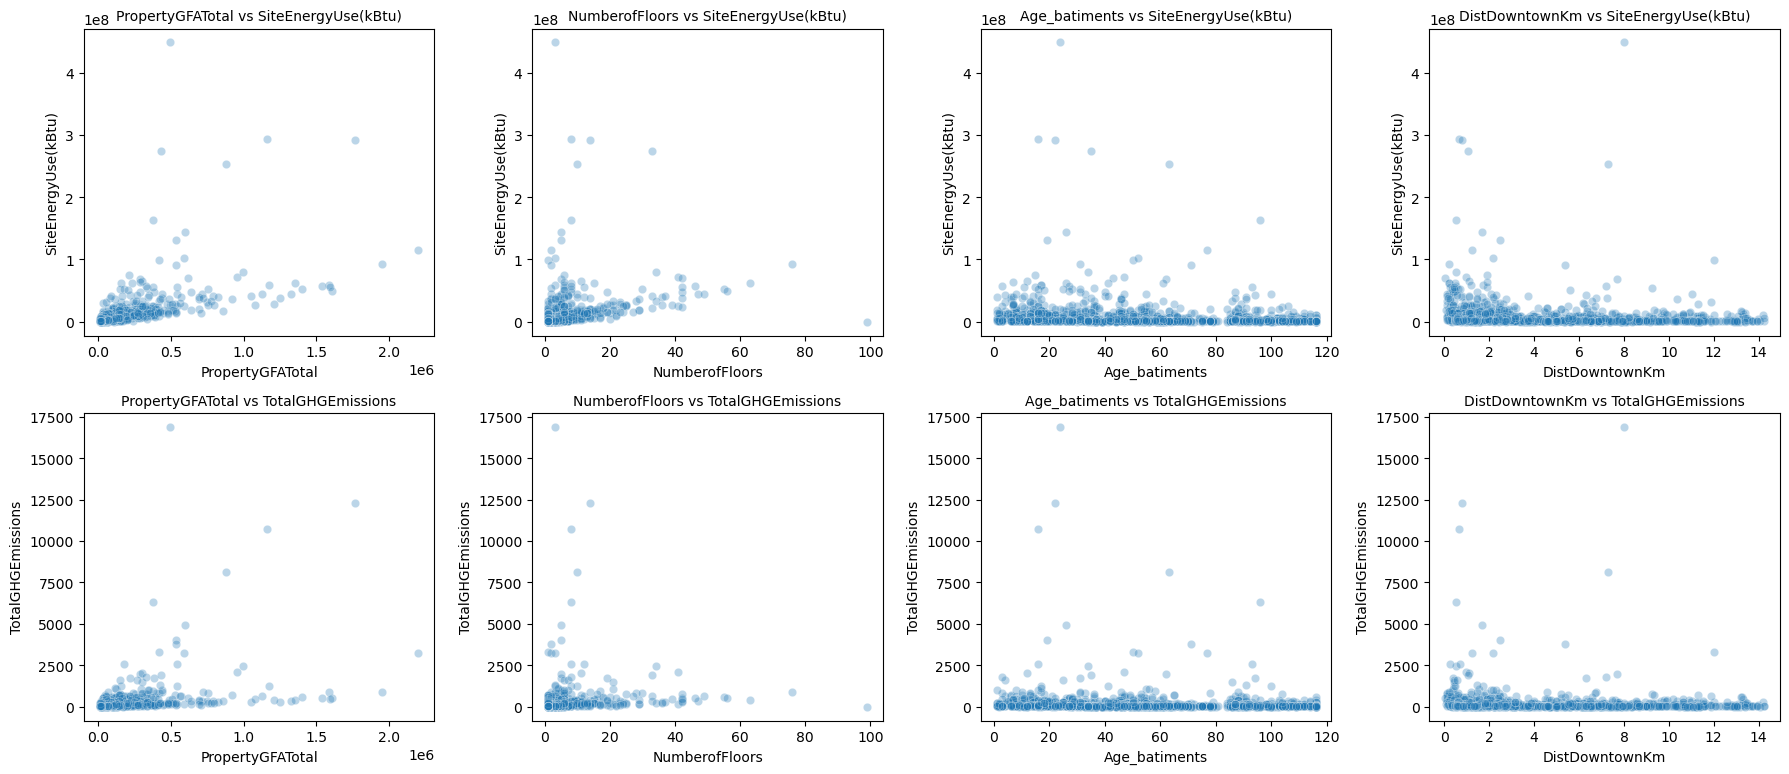

In [30]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8))  # grille de 2 lignes (une par cible) x 4 colonnes (une par feature)
feats = ["PropertyGFATotal", "NumberofFloors", "Age_batiments", "DistDowntownKm"]  # les 4 features numériques à comparer aux cibles
for i, (col, lib) in enumerate(cibles.items()):  # i = ligne de la grille (0 = énergie, 1 = CO2)
    for a, f in zip(ax[i], feats):  # une case de la ligne pour chaque feature
        sns.scatterplot(data=model_df, x=f, y=col, alpha=0.3, ax=a)  # nuage de points feature contre cible
        a.set_title(f"{f} vs {col}", fontsize=10) 
plt.tight_layout(); plt.show() 

In [31]:
# Variable qualitative vs cibles : type de propriété principal (médiane)
med = model_df.groupby("PrimaryPropertyType")[targets].median().sort_values("SiteEnergyUse(kBtu)", ascending=False)  # médiane des deux cibles pour chaque type de propriété, du plus consommateur au moins consommateur
med.round(0)  # affiche le tableau arrondi

,SiteEnergyUse(kBtu),TotalGHGEmissions
PrimaryPropertyType,,
Hospital,143423024.0,4906.0
Laboratory,18205582.0,505.0
Large Office,13239050.0,131.0
Supermarket / Grocery Store,9290214.0,227.0
Senior Care Community,7366733.0,203.0
Hotel,6120112.0,196.0
Medical Office,5279340.0,74.0
University,5000717.0,104.0
Restaurant,4475650.0,127.0


#### Séparation X / y

In [32]:
X = model_df[num_features + cat_features]  # X : le tableau des features (ce que le modèle voit)
y = model_df[targets]          # DataFrame à deux colonnes : une cible par modèle
print(X.shape, y.shape)  # vérifie que X et y ont le même nombre de lignes

(1479, 15) (1479, 2)


#### Encodage des variables catégorielles
- `OneHotEncoder` pour les variables catégorielles (nominales, sans ordre ; `LabelEncoder` ne convient qu'à une cible ou à des variables ordinales). `max_categories=15` limite la dimension.
- Les variables numériques : les valeurs vides (4 valeurs de `LargestUseShare`) sont remplacées par la médiane, car la régression linéaire et le SVR refusent les vides.
  `StandardScaler` est utilisé pour mettre à la même echelle les valeurs. Utile pour le SVR qui additionne les valeurs entre elle après une mise au carré (variable contenant une petite valeur ne pèse pas). Le random forest n'est pas sensible car il fait une comparaison de valeur (inf ou sup à 10 par exemple) à chaque variable puis donne une valeur 0 ou  1.


In [33]:
#Traitement des données avant utilisation des modèles
preprocessor = ColumnTransformer([  # applique un traitement différent selon le type de colonne
    ("num", Pipeline([
        ("imp",SimpleImputer(strategy="median")), # variables numériques : valeurs brutes, seules les valeurs vides sont remplacées par la médiane (la régression linéaire et le SVR refusent les vides)
        ("scal", StandardScaler())]),
        num_features),#standardiser les données numérique pour mettre à la même echelle
    ("cat", OneHotEncoder(handle_unknown="ignore", max_categories=15, sparse_output=False), cat_features),])  #variables catégorielles, une colonne 0/1 par modalité (max 15, modalité inconnue ignorée au test)


### Comparaison de différents modèles supervisés

**Démarche commune à tous les modèles et aux deux cibles** :
1. Un **unique** split train/test (80/20) : mêmes lignes pour tous les modèles et les deux cibles.
2. Validation croisée sur le train (`cross_validate`) → R², MAE, RMSE sur train et validation.
3. Entraînement final sur tout le train, évaluation sur le test.
5. Trois familles de modèles testées : **linéaire** (régression linéaire), **à noyau / SVM** (SVR), **à base d'arbres** (Random Forest)

In [34]:
# 1) SPLIT D'ABORD, sur les 1479 bâtiments propres
# stratify : le test contient des petits, moyens et gros bâtiments dans les mêmes proportions que le train
strat = pd.qcut(np.log(y["SiteEnergyUse(kBtu)"]), 5, labels=False) #même proportion de petits, moyen et grans batiements 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=strat)
print("Après split :", X_train.shape, X_test.shape)

#seuils quantiles calculés pour le train uniquement
seuils = {}
masque_train = pd.Series(True, index=y_train.index)
for t in targets:
    q_low, q_high = y_train[t].quantile([0.01, 0.99]) #calcul du quantile pour le train
    seuils[t] = (q_low, q_high) 
    masque_train &= y_train[t].between(q_low, q_high)
    print(f"{t} : seuils [{q_low:,.1f} ; {q_high:,.1f}]")

#affichage avant après seuils
avant = len(y_train)
X_train, y_train = X_train[masque_train], y_train[masque_train]   # extrêmes retirés du train seulement
print(f"Retrait des extrêmes (train) : {avant} -> {len(y_train)} (-{avant - len(y_train)})")

#calcul du 
masque_test = pd.Series(True, index=y_test.index)
for t in targets:
    masque_test &= y_test[t].between(*seuils[t])
print(f"Test : {len(y_test)} bâtiments (dont {masque_test.sum()} hors extrêmes, {len(y_test) - masque_test.sum()} extrêmes conservés)")

#Split en 5 partie des tests
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluer_modele(nom, estimateur, target):
    modele = Pipeline([("prep", preprocessor), ("model", estimateur)])  # préparation puis modèle
    scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}  # 3 métriques
    cvres = cross_validate(modele, X_train, y_train[target], cv=cv, scoring=scoring,
                           return_train_score=True, n_jobs=-1)  # validation croisée sur le train
    modele.fit(X_train, y_train[target])  # entraînement final sur tout le train
    pred = modele.predict(X_test)  # prédictions sur le test
    return {
        "Modèle": nom,
        "R2 train split": cvres["train_r2"].mean(), 
        "R2 val split": cvres["test_r2"].mean(),
        "MAE val split": -cvres["test_mae"].mean(), 
        "RMSE val split": -cvres["test_rmse"].mean(),
        "R2 test incorrect": r2_score(y_test[target], pred),                #pas de filtre extreme sur test
        "R2 test (final, hors extreme)": r2_score(y_test[target][masque_test], pred[masque_test.values]),  #sans filtre extrele sur test
        "MAE test": mean_absolute_error(y_test[target], pred),
        "RMSE test": np.sqrt(mean_squared_error(y_test[target], pred)),
    }

Après split : (1183, 15) (296, 15)
SiteEnergyUse(kBtu) : seuils [175,139.3 ; 73,034,659.5]
TotalGHGEmissions : seuils [1.5 ; 2,154.5]
Retrait des extrêmes (train) : 1183 -> 1155 (-28)
Test : 296 bâtiments (dont 289 hors extrêmes, 7 extrêmes conservés)


In [35]:
modeles = {  # dictionnaire des modèles à comparer (paramètres par défaut)
    "Dummy (moyenne)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "SVR": SVR(),
    "Random Forest Standard": RandomForestRegressor(random_state=42),
    "Random Forest Reglé": RandomForestRegressor(n_estimators=200, max_depth=8, max_features=1,
                                                 min_samples_leaf=3, random_state=42)
    
}
resultats = {}  # dictionnaire qui stockera le tableau de résultats de chaque cible
for t in targets:  # pour chaque cible (énergie puis CO2)
    resultats[t] = pd.DataFrame([evaluer_modele(nom, m, t) for nom, m in modeles.items()]).set_index("Modèle")  # évalue chaque modèle et met les résultats dans un tableau
    print(f"\nCible : {t}")
    print(resultats[t].round(3).to_string())  # affiche le tableau arrondi


Cible : SiteEnergyUse(kBtu)
                        R2 train split  R2 val split  MAE val split  RMSE val split  R2 test incorrect  R2 test (final, hors extreme)     MAE test     RMSE test
Modèle                                                                                                                                                          
Dummy (moyenne)                  0.000        -0.005    6391828.359    1.017526e+07             -0.001                         -0.004  6823298.191  1.442296e+07
Régression linéaire              0.635         0.571    3534300.063    6.601586e+06              0.682                          0.653  3340399.736  8.132090e+06
SVR                             -0.144        -0.146    5262138.831    1.087225e+07             -0.092                         -0.137  5791038.849  1.506438e+07
Random Forest Standard           0.946         0.582    3305307.836    6.445766e+06              0.611                          0.689  3379435.421  8.993968e+06
Rando

**Interprétation** (validation croisée sur le train ; le test sert de contrôle final)

*Cible énergie (`SiteEnergyUse`)*
- **Dummy** : R² ≈ 0 et MAE ≈ 6,4 M kBtu en validation. C'est le plancher : tout vrai modèle doit faire mieux.
- **Régression linéaire** : R² val 0,57 pour 0,64 en train, donc très peu de sur-apprentissage. Simple et stable, MAE val 3,53 M kBtu.
- **SVR** : R² val négatif (-0,15). Ce n'est pas un verdict sur la famille SVM : avec ses réglages par défaut (`C=1`, `epsilon=0,1`), le SVR est inadapté à une cible qui se compte en millions de kBtu, et prédit presque une constante. À ne pas interpréter comme un modèle « mauvais en soi ».
- **Random Forest standard** : R² val 0,58 mais R² train 0,95 : fort sur-apprentissage (il apprend le train par cœur).
- **Random Forest réglé** (profondeur limitée, feuilles plus grosses) : R² train 0,83, R² val 0,60 et MAE val 3,28 M kBtu, le meilleur des modèles évaluables. Limiter la profondeur réduit l'écart train/validation.

*Cible CO2 (`TotalGHGEmissions`)*
- Tâche **plus difficile** : les émissions dépendent de la source d'énergie (gaz, vapeur, électricité), que nous avons exclue des features pour éviter la fuite de données.
- **Régression linéaire** : R² val 0,29. **Random Forest standard** : 0,39 (train 0,92). **Random Forest réglé** : R² val 0,43 et MAE val 86 t, le meilleur. SVR : même problème d'échelle que pour l'énergie (R² négatif).

*Choix* : le **Random Forest réglé** est retenu pour les deux cibles, puis optimisé par GridSearch. Raisons :
1. Il a la meilleure MAE et le meilleur R² en validation croisée sur les deux cibles. L'écart avec la régression linéaire est **modeste pour l'énergie** (R² 0,60 contre 0,57, dans la variation entre découpages d'environ ± 0,06 à 0,08) et **net pour le CO2** (0,43 contre 0,29).
2. Il capte les relations **non linéaires** (l'effet de la surface dépend du type d'usage), ce qu'une droite ne fait pas.
3. Il fournit une importance des variables native (`feature_importances_`), demandée pour l'interprétation.
4. Le sur-apprentissage est réduit en limitant la profondeur et en imposant des feuilles plus grosses (train 0,83 contre 0,95 pour la version standard), mais il reste visible (train 0,83 / validation 0,59).

*Précaution sur le test* : sur le jeu de test (296 bâtiments dont 7 très gros), la régression linéaire obtient un R² égal ou supérieur à celui du Random Forest. Ce jeu est petit et sensible aux quelques géants. Le choix du modèle repose donc sur la **validation croisée** (5 découpages) et non sur le test : choisir d'après le test reviendrait à l'utiliser pour décider, et il ne serait plus une évaluation honnête.

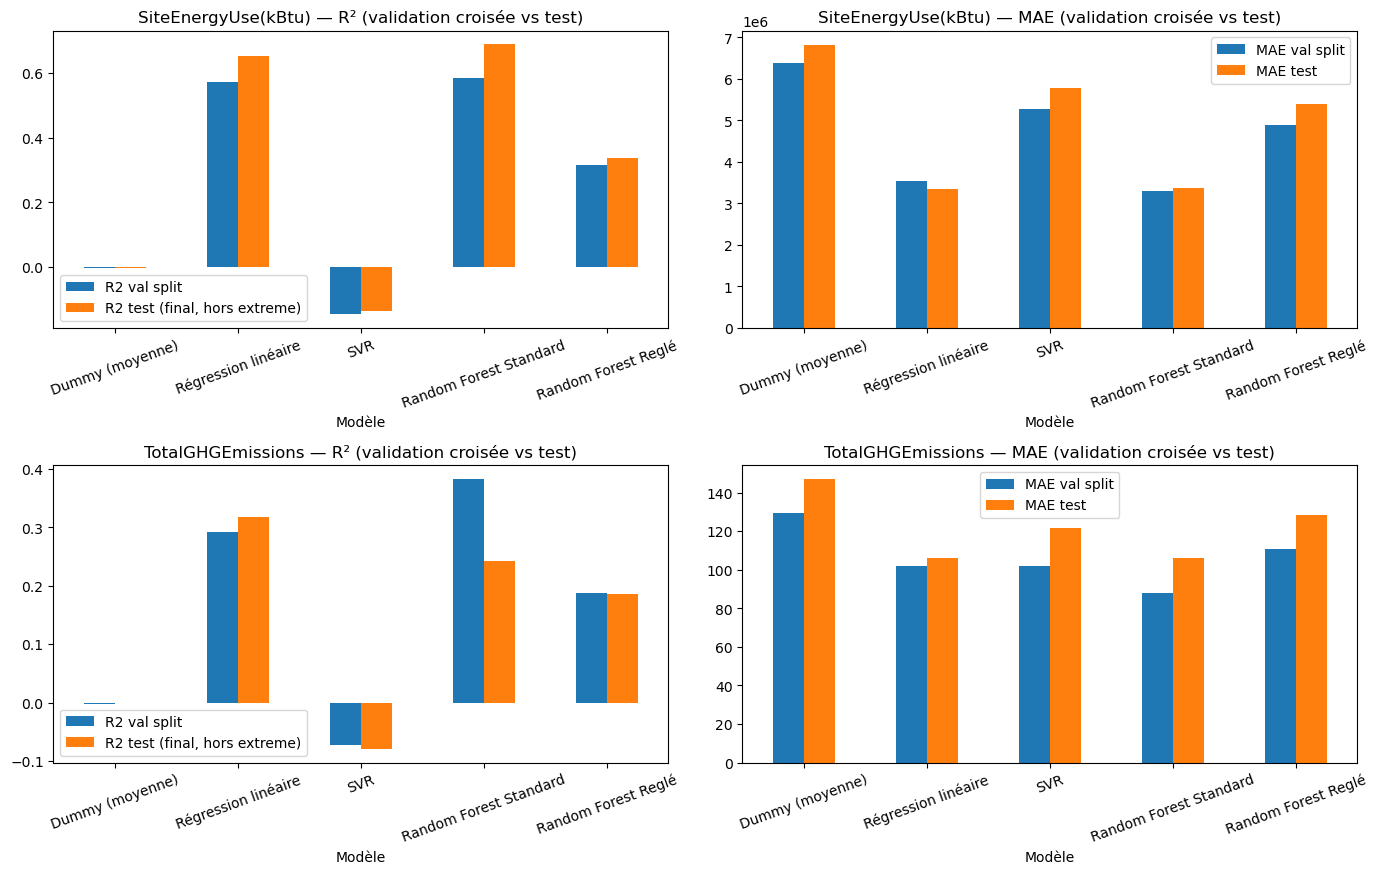

In [36]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))  # grille 2 x 2 : lignes = cibles, colonnes = R² / MAE
for i, t in enumerate(targets):  # i = ligne de la grille
    resultats[t][["R2 val split", "R2 test (final, hors extreme)"]].plot.bar(ax=ax[i, 0], rot=20); ax[i, 0].set_title(f"{t} — R² (validation croisée vs test)")  # barres du R² : validation croisée contre test
    resultats[t][["MAE val split", "MAE test"]].plot.bar(ax=ax[i, 1], rot=20); ax[i, 1].set_title(f"{t} — MAE (validation croisée vs test)")  # barres de la MAE : validation croisée contre test
plt.tight_layout(); plt.show()  # ajuste les marges puis affiche

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn. 

### Explication pour les réglages

• n_estimators: Indique le nombre d'arbres de décision dans la forêt. Plus cette valeur est élevée, plus le modèle est stable et précis, mais plus le temps de calcul augmente.
• max_depth: Définit la profondeur maximale de chaque arbre. Si le paramètre est None, les nœuds se développent jusqu'à ce que toutes les feuilles soient pures ou contiennent moins de min_samples_split échantillons.
• max_features: Détermine le nombre de variables à examiner lors de la recherche du meilleur découpage. Par défaut (1.0 ou "sqrt" selon les versions), cela permet de décorréler les arbres et de réduire le surapprentissage.
• min_samples_leaf: Le nombre minimal d'échantillons requis pour être à une feuille. Un niveau plus élevé lisse les prédictions.
• random_state: Contrôle le caractère aléatoire du tirage des échantillons et des caractéristiques pour assurer la reproductibilité des résultats.

### Pourquoi la GridSearch optimise la MAE

La GridSearch a besoin d'**un critère unique** pour classer les combinaisons d'hyperparamètres. Nous choisissons la **MAE** (erreur absolue moyenne) pour ces raisons :

1. **Elle se lit dans l'unité du problème** : « le modèle se trompe en moyenne de ± X kBtu (ou X tonnes) ». C'est la phrase qu'on peut dire à un décideur.
2. **Elle est robuste aux très gros bâtiments.** Le R² et le RMSE élèvent les erreurs au carré : quelques bâtiments à plusieurs centaines de millions de kBtu (maximum 448 M) pèseraient plus que tout le reste, et la GridSearch retiendrait des réglages faits pour ces quelques géants au détriment de la majorité des bâtiments. La MAE les pondère proportionnellement. C'est la même logique que le choix de la médiane et des quantiles dans l'analyse exploratoire.

*Limites à connaître* : la MAE reste une erreur **absolue** (se tromper de 20 % sur un hôpital pèse plus que sur une école), et elle punit moins les très grosses erreurs que le RMSE. Si l'objectif était une erreur **relative**, il faudrait une autre métrique (par exemple l'erreur relative médiane) ou une cible transformée.

In [37]:
param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [8, 10],
    "model__min_samples_leaf": [5, 10],
    "model__criterion": ['poisson']
}   

def gridsearch_rf(target, log_cible=True):
    modele = Pipeline([("prep", preprocessor), ("model", RandomForestRegressor(random_state=42))])
    if log_cible:   # entraîne en log, mais les prédictions et métriques restent en unités réelles
        modele = TransformedTargetRegressor(regressor=modele)
    prefixe = "regressor__" if log_cible else ""
    grille = {prefixe + k: v for k, v in param_grid.items()}

    #Déterminer le score qu'on veut optimiser
    scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}  # les 3 métriques sont calculées
    
    gs = GridSearchCV(modele, grille, cv=cv, scoring=scoring, refit="mae",
                      return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y_train[target])

    i, cvres = gs.best_index_, gs.cv_results_      # i = position de la meilleure combinaison
    pred = gs.predict(X_test)                      # modèle final réentraîné sur tout le train

    resultats = {
        "R2 train split": cvres["mean_train_r2"][i],
        "R2 val split": cvres["mean_test_r2"][i],
        "MAE val split": -cvres["mean_test_mae"][i],
        "RMSE val split": -cvres["mean_test_rmse"][i],
        "R2 test incorrect": r2_score(y_test[target], pred),                                              # test complet
        "R2 test (final, hors extreme)": r2_score(y_test[target][masque_test], pred[masque_test.values]),  # test sans extrêmes
        "MAE test": mean_absolute_error(y_test[target], pred),
        "RMSE test": np.sqrt(mean_squared_error(y_test[target], pred)),
    }
    return gs, resultats

tous = {}
grids = {}   # on garde la GridSearch de chaque cible : nécessaire pour calculer l'importance des variables ensuite
for target in targets:
    grids[target], tous[target] = gridsearch_rf(target)
    print(f"{target} | meilleurs paramètres :", {k.split("__")[-1]: v for k, v in grids[target].best_params_.items()})
pd.DataFrame(tous).round(3)

SiteEnergyUse(kBtu) | meilleurs paramètres : {'criterion': 'poisson', 'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}
TotalGHGEmissions | meilleurs paramètres : {'criterion': 'poisson', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 300}


,SiteEnergyUse(kBtu),TotalGHGEmissions
R2 train split,0.796,0.717
R2 val split,0.590,0.439
MAE val split,3273776.193,86.162
RMSE val split,6446056.700,167.156
R2 test incorrect,0.564,0.277
"R2 test (final, hors extreme)",0.662,0.355
MAE test,3521994.171,103.921
RMSE test,9521909.565,322.933


### Importance des variables (feature importance)
Le meilleur modèle étant un Random Forest, on utilise son importance native (`feature_importances_`), complétée par la **permutation importance** sur le jeu de test comme contre-vérification.

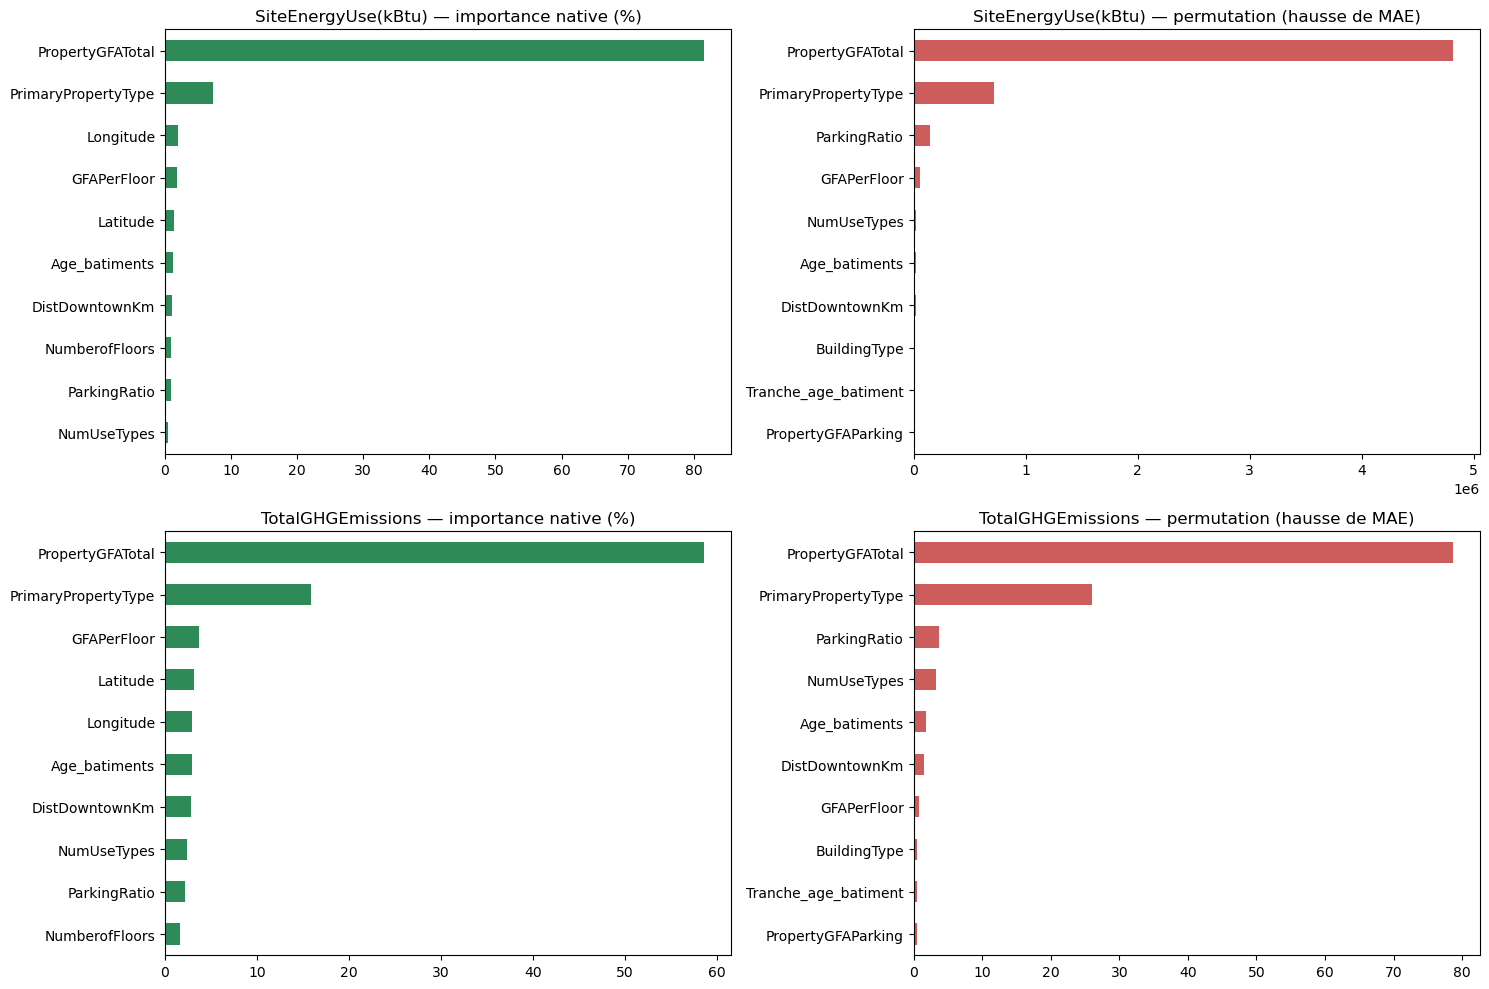

In [38]:
# Importance globale des variables, pour chaque cible
def origine(n):  # retrouve la variable d'origine d'une colonne issue de l'encodage one-hot
    for c in cat_features:  # pour chaque variable catégorielle
        if n.startswith(c + "_"):  # ex. "PrimaryPropertyType_Hotel" vient de "PrimaryPropertyType"
            return c  # on renvoie la variable d'origine
    return n  # sinon la colonne est déjà une variable d'origine

imps_groupe, perms = {}, {}  # dictionnaires : importance native puis importance par permutation, par cible
for t in targets:  # pour chaque cible
    best = grids[t].best_estimator_  # meilleur modèle trouvé par la GridSearch
    pipe = best.regressor_ if hasattr(best, "regressor_") else best  # extrait le pipeline (retire l'enveloppe TransformedTargetRegressor si présente)
    rf = pipe.named_steps["model"]  # le Random Forest dans le pipeline
    noms = [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]  # noms des colonnes après préparation
    imp = pd.Series(rf.feature_importances_, index=noms)  # importance native de chaque colonne
    imps_groupe[t] = imp.groupby(origine).sum().sort_values(ascending=False)  # additionne les modalités d'une même variable
    perm = permutation_importance(best, X_test, y_test[t], scoring="neg_mean_absolute_error",
                                  n_repeats=10, random_state=42, n_jobs=-1)  # mélange chaque variable du test 10 fois et mesure la perte de précision
    perms[t] = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)  # hausse moyenne de MAE par variable

fig, ax = plt.subplots(2, 2, figsize=(15, 10))  # grille 2 x 2 : lignes = cibles, colonnes = méthodes
for i, t in enumerate(targets):  # i = ligne de la grille
    (imps_groupe[t].head(10)[::-1] * 100).plot.barh(ax=ax[i, 0], color="seagreen")  # importance native en % du modèle, 10 premières variables
    ax[i, 0].set_title(f"{t} — importance native (%)")  # titre
    perms[t].head(10)[::-1].plot.barh(ax=ax[i, 1], color="indianred")  # importance par permutation
    ax[i, 1].set_title(f"{t} — permutation (hausse de MAE)")  # titre
plt.tight_layout(); plt.show()  # ajuste les marges puis affiche

**Interprétation de l'importance des variables** (modèle final, test de permutation sur le jeu de test)
- **Énergie** : la **surface totale** domine largement (80 % de l'importance native ; la permutation confirme : mélanger cette variable augmente la MAE d'environ 4,9 M kBtu). Le **type de propriété** vient ensuite (~8 %), puis le nombre d'étages, la longitude et la surface par étage (2 à 3 % chacun).
- **CO2** : la surface reste la première variable (60 %) mais le **type de propriété pèse beaucoup plus** (~22 %, permutation : +24 t de MAE). Comme nous avons exclu les sources d'énergie (gaz, vapeur) pour éviter la fuite de données, le type de propriété joue le rôle d'indicateur de la technologie de chauffage et d'usage.
- Les méthodes (importance native et permutation) s'accordent sur l'ordre : surface, puis type de propriété.
- *Précaution* : plusieurs variables de taille (surface totale, surface de parking, surface par étage, étages) sont liées entre elles, ce qui peut répartir ou gonfler l'importance de la surface. L'importance indique ce que le modèle utilise, pas une relation de cause à effet.

### Lecture métier des erreurs

In [39]:
# Lecture métier : de combien se trompe le modèle final, en pourcentage de la vraie valeur ?
for t in targets:  # pour chaque cible
    pred = grids[t].predict(X_test)  # prédictions du modèle final sur tout le test (extrêmes inclus)
    err_rel = np.abs(pred - y_test[t]) / y_test[t]  # erreur de chaque bâtiment en % de sa vraie valeur
    print(f"{t} : erreur relative médiane {err_rel.median():.0%} | 75 % des bâtiments à moins de {err_rel.quantile(.75):.0%} près")  # affichage lisible

SiteEnergyUse(kBtu) : erreur relative médiane 43% | 75 % des bâtiments à moins de 84% près
TotalGHGEmissions : erreur relative médiane 65% | 75 % des bâtiments à moins de 209% près


### Conclusion et limites
- **Modèle retenu** : Random Forest réglé par GridSearch (critère MAE), pour l'énergie et pour le CO2.
- **Niveau de précision** : sur le test complet (extrêmes inclus), R² ≈ 0,66 pour l'énergie et ≈ 0,35 pour le CO2. L'erreur relative médiane (cellule précédente) donne l'ordre de grandeur de la précision : le modèle sert à **estimer un ordre de grandeur et prioriser les bâtiments à relever**, pas à remplacer une mesure, surtout pour le CO2.
- **Limites** : sur-apprentissage encore visible (train 0,84 / validation 0,59 pour l'énergie), test de petite taille (296 bâtiments, dont 7 très gros), pas de données sur l'occupation ou les équipements, sources d'énergie volontairement exclues, SVR non comparable car réglé avec ses paramètres par défaut sur une cible non mise à l'échelle.

# Partie 2 — Exposer le modèle via une API (BentoML)

**Objectif** : permettre à un propriétaire de bâtiment d'envoyer quelques informations simples et d'obtenir en retour, en temps réel, une estimation de la **consommation d'énergie** et des **émissions de CO2** de son bâtiment.

```
JSON envoyé par l'utilisateur  →  validation (Pydantic)  →  feature engineering (identique au notebook)  →  Random Forest énergie + Random Forest CO2  →  JSON de réponse
```

**Choix de conception**

| Choix | Pourquoi |
|---|---|
| **Un seul endpoint `/predict`**, deux modèles derrière | Les deux cibles utilisent les mêmes features : un seul appel renvoie énergie **et** CO2. |
| L'utilisateur envoie des **données brutes** (année de construction, surface, quartier…) | Il ne connaît pas nos transformations (âge, tranche d'âge, distance au centre, one-hot…). Le service les recalcule avec **exactement** les formules du feature engineering. |
| Les **features et leur ordre** sont sauvegardés avec le modèle (`custom_objects`) | Au moment de l'inférence, les colonnes doivent arriver dans le même ordre qu'à l'entraînement. |
| **Pas de `Runner`** | Concept archivé par BentoML : les modèles sont chargés directement dans le service (`__init__`). |
| Validation **Pydantic** | Rejeter les valeurs incohérentes avant qu'elles n'atteignent le modèle (un Random Forest répond toujours, même à une entrée absurde). |

Fichiers produits : `schemas.py` (validation), `service.py` (API), `bentofile.yaml` (packaging / Docker).

### 1. Sauvegarder les deux modèles dans le Model Store de BentoML
On sauvegarde le **meilleur modèle de chaque GridSearch** (préparation + Random Forest, déjà entraîné sur le train). `custom_objects` conserve avec le modèle la liste des features **dans l'ordre d'entraînement** ; `metadata` garde la trace des performances et des hyperparamètres.

In [40]:
import bentoml  # bentoml : sauvegarde le modèle puis le transforme en API web
import requests  # requests : envoie des requêtes HTTP à l'API pour la tester
import subprocess, sys, time  # subprocess : lance le serveur depuis le notebook ; sys : chemin de Python ; time : pauses entre deux essais

features_modele = num_features + cat_features  # features DANS L'ORDRE vu par le modèle à l'entraînement (c'est l'ordre des colonnes de X)
noms_modeles = {"SiteEnergyUse(kBtu)": "seattle_energy_rf", "TotalGHGEmissions": "seattle_co2_rf"}  # nom BentoML du modèle de chaque cible

for t in targets:  # pour chaque cible (énergie puis CO2)
    modele_bento = bentoml.sklearn.save_model(  # enregistre le modèle dans le Model Store local de BentoML
        noms_modeles[t],  # nom sous lequel le modèle sera retrouvé par le service
        grids[t].best_estimator_,  # meilleur modèle de la GridSearch (préparation + Random Forest), réentraîné sur tout le train
        custom_objects={"features": features_modele, "target": t},  # objets sauvegardés avec le modèle : features dans l'ordre + cible prédite
        metadata={  # informations de traçabilité (visibles avec `bentoml models get`)
            "target": t,  # cible prédite par ce modèle
            "best_params": {k.split("__")[-1]: v for k, v in grids[t].best_params_.items()},  # hyperparamètres retenus par la GridSearch
            "r2_test_hors_extremes": float(tous[t]["R2 test (final, hors extreme)"]),  # R² sur le test sans valeurs extrêmes
            "mae_test": float(tous[t]["MAE test"]),  # erreur absolue moyenne sur le test complet (unité de la cible)
        },
    )
    print(f"{t} -> {modele_bento.tag}")  # affiche le nom complet (nom:version) du modèle sauvegardé

SiteEnergyUse(kBtu) -> seattle_energy_rf:ubzehh6nm2ofkaav
TotalGHGEmissions -> seattle_co2_rf:udet7zgnm2vkqaav


In [41]:
import sys, sklearn
print(sys.executable, sklearn.__version__)

C:\ProgramData\anaconda3\python.exe 1.9.1
